In [1]:
import numpy as np
import fastplotlib as fpl
import tifffile

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
import cv2
import logging
from math import sqrt
import matplotlib.animation as animation
import matplotlib.pyplot as plt
from multiprocessing import current_process
import numpy as np
import scipy
import scipy.ndimage as nd
from scipy.ndimage import center_of_mass, correlate
import scipy.sparse as spr
from skimage.morphology import disk
from sklearn.decomposition import NMF, FastICA
from sklearn.exceptions import ConvergenceWarning
from sklearn.utils.extmath import randomized_svd, squared_norm, randomized_range_finder
import sys
import warnings

In [3]:
def imblur(Y, sig=5, siz=11, nDimBlur=None, kernel=None, opencv=True):
    """
    Spatial filtering with a Gaussian or user defined kernel

    The parameters are specified in GreedyROI

    Args:
        Y: np.ndarray
            d1 x d2 [x d3] x T movie, raw data.

        sig: [optional] list,tuple
            half size of neurons

        siz: [optional] list,tuple
            size of filter kernel (default 2*sig + 1).

        nDimBlur: [optional]
            if you want to specify the number of dimension

        kernel: [optional]
            if you want to specify a kernel

        opencv: [optional]
            if you want to process to the blur using OpenCV method

    Returns:
        the blurred image
    """
    # TODO: document (jerem)
    if kernel is None:
        if nDimBlur is None:
            nDimBlur = Y.ndim - 1
        else:
            nDimBlur = np.min((Y.ndim, nDimBlur))

        if np.isscalar(sig):
            sig = sig * np.ones(nDimBlur)

        if np.isscalar(siz):
            siz = siz * np.ones(nDimBlur)

        X = Y.copy()
        if opencv and nDimBlur == 2:
            if X.ndim > 2:
                # if we are on a video we repeat for each frame
                for frame in range(X.shape[-1]):
                    if sys.version_info >= (3, 0):
                        X[:, :, frame] = cv2.GaussianBlur(X[:, :, frame], tuple(
                            siz), sig[0], None, sig[1], cv2.BORDER_CONSTANT)
                    else:
                        X[:, :, frame] = cv2.GaussianBlur(X[:, :, frame], tuple(siz), sig[
                                                          0], sig[1], cv2.BORDER_CONSTANT, 0)

            else:
                if sys.version_info >= (3, 0):
                    X = cv2.GaussianBlur(
                        X, tuple(siz), sig[0], None, sig[1], cv2.BORDER_CONSTANT)
                else:
                    X = cv2.GaussianBlur(
                        X, tuple(siz), sig[0], sig[1], cv2.BORDER_CONSTANT, 0)
        else:
            for i in range(nDimBlur):
                h = np.exp(-np.arange(-np.floor(siz[i] / 2),
                                       np.floor(siz[i] / 2) + 1)**2 / (2 * sig[i]**2))
                h /= np.sqrt(h.dot(h))
                shape = [1] * len(Y.shape)
                shape[i] = -1
                X = correlate(X, h.reshape(shape), mode='constant')

    else:
        X = correlate(Y, kernel[..., np.newaxis], mode='constant')
        # for t in range(np.shape(Y)[-1]):
        #    X[:,:,t] = correlate(Y[:,:,t],kernel,mode='constant', cval=0.0)

    return X


In [4]:
def finetune(Y, cin, nIter=5):
    """compute a initialized version of A and C

    Args:
        Y:  D1*d2*T*K patches

        c: array T*K
            the initial calcium traces

        nIter: int
            True indicates that time is listed in the last axis of Y (matlab format)
            and moves it in the front

    Returns:
    a: array (d1,D2) the computed A as l2(Y*C)/Y*C

    c: array(T) C as the sum of As on x*y axis
"""
    debug_ = False
    if debug_:
        import os
        f = open('_LOG_1_' + str(os.getpid()), 'w+')
        f.write('Y:' + str(np.mean(Y)) + '\n')
        f.write('cin:' + str(np.mean(cin)) + '\n')
        f.close()

    # we compute the multiplication of patches per traces ( non negatively )
    for _ in range(nIter):
        a = np.maximum(np.dot(Y, cin), 0)
        a = a / np.sqrt(np.sum(a**2) + np.finfo(np.float32).eps)  # compute the l2/a
        # c as the variation of those patches
        cin = np.sum(Y * a[..., np.newaxis], tuple(np.arange(Y.ndim - 1)))

    return a, cin


In [5]:
def greedyROI(Y, nr=30, gSig=[5, 5], gSiz=[11, 11], nIter=5, kernel=None, nb=1,
              rolling_sum=False, rolling_length=100, seed_method='auto'):
    """
    Greedy initialization of spatial and temporal components using spatial Gaussian filtering

    Args:
        Y: np.array
            3d or 4d array of fluorescence data with time appearing in the last axis.

        nr: int
            number of components to be found

        gSig: scalar or list of integers
            standard deviation of Gaussian kernel along each axis

        gSiz: scalar or list of integers
            size of spatial component

        nIter: int
            number of iterations when refining estimates

        kernel: np.ndarray
            User specified kernel to be used, if present, instead of Gaussian (default None)

        nb: int
            Number of background components

        rolling_max: boolean
            Detect new components based on a rolling sum of pixel activity (default: True)

        rolling_length: int
            Length of rolling window (default: 100)

        seed_method: str {'auto', 'manual', 'semi'}
            methods for choosing seed pixels
            'semi' detects nr components automatically and allows to add more manually
            if running as notebook 'semi' and 'manual' require a backend that does not
            inline figures, e.g. %matplotlib tk

    Returns:
        A: np.array
            2d array of size (# of pixels) x nr with the spatial components. Each column is
            ordered columnwise (matlab format, order='F')

        C: np.array
            2d array of size nr X T with the temporal components

        center: np.array
            2d array of size nr x 2 [ or 3] with the components centroids

    Author:
        Eftychios A. Pnevmatikakis and Andrea Giovannucci based on a matlab implementation by Yuanjun Gao
            Simons Foundation, 2015

    See Also:
        http://www.cell.com/neuron/pdf/S0896-6273(15)01084-3.pdf


    """
    logging.info("Greedy initialization of spatial and temporal components using spatial Gaussian filtering")
    d = np.shape(Y)
    Y[np.isnan(Y)] = 0
    med = np.median(Y, axis=-1)
    Y = Y - med[..., np.newaxis]
    gHalf = np.array(gSiz) // 2
    gSiz = 2 * gHalf + 1
    # we initialize every values to zero
    if seed_method.lower() == 'manual':
        nr = 0
    A = np.zeros((np.prod(d[0:-1]), nr), dtype=np.float32)
    C = np.zeros((nr, d[-1]), dtype=np.float32)
    center = np.zeros((nr, Y.ndim - 1), dtype='uint16')

    rho = imblur(Y, sig=gSig, siz=gSiz, nDimBlur=Y.ndim - 1, kernel=kernel)
    if rolling_sum:
        logging.info('Using rolling sum for initialization (RollingGreedyROI)')
        rolling_filter = np.ones(
            (rolling_length), dtype=np.float32) / rolling_length
        rho_s = scipy.signal.lfilter(rolling_filter, 1., rho**2)
        v = np.amax(rho_s, axis=-1)
    else:
        logging.info('Using total sum for initialization (GreedyROI)')
        v = np.sum(rho**2, axis=-1)

    if seed_method.lower() != 'manual':
        for k in range(nr):
            # we take the highest value of the blurred total image and we define it as
            # the center of the neuron
            ind = np.argmax(v)
            ij = np.unravel_index(ind, d[0:-1])
            for c, i in enumerate(ij):
                center[k, c] = i

            # we define a squared size around it
            ijSig = [[np.maximum(ij[c] - gHalf[c], 0), np.minimum(ij[c] + gHalf[c] + 1, d[c])]
                     for c in range(len(ij))]
            # we create an array of it (fl like) and compute the trace like the pixel ij through time
            dataTemp = np.array(
                Y[tuple([slice(*a) for a in ijSig])].copy(), dtype=np.float32)
            traceTemp = np.array(np.squeeze(rho[ij]), dtype=np.float32)

            coef, score = finetune(dataTemp, traceTemp, nIter=nIter)
            C[k, :] = np.squeeze(score)
            dataSig = coef[..., np.newaxis] * \
                score.reshape([1] * (Y.ndim - 1) + [-1])
            xySig = np.meshgrid(*[np.arange(s[0], s[1])
                                  for s in ijSig], indexing='xy')
            arr = np.array([np.reshape(s, (1, np.size(s)), order='F').squeeze()
                            for s in xySig], dtype=int)
            indices = np.ravel_multi_index(arr, d[0:-1], order='F')

            A[indices, k] = np.reshape(
                coef, (1, np.size(coef)), order='C').squeeze()
            Y[tuple([slice(*a) for a in ijSig])] -= dataSig.copy()
            if k < nr - 1 or seed_method.lower() != 'auto':
                Mod = [[np.maximum(ij[c] - 2 * gHalf[c], 0),
                        np.minimum(ij[c] + 2 * gHalf[c] + 1, d[c])] for c in range(len(ij))]
                ModLen = [m[1] - m[0] for m in Mod]
                Lag = [ijSig[c] - Mod[c][0] for c in range(len(ij))]
                dataTemp = np.zeros(ModLen)
                dataTemp[tuple([slice(*a) for a in Lag])] = coef
                dataTemp = imblur(dataTemp[..., np.newaxis],
                                  sig=gSig, siz=gSiz, kernel=kernel)
                temp = dataTemp * score.reshape([1] * (Y.ndim - 1) + [-1])
                rho[tuple([slice(*a) for a in Mod])] -= temp.copy()
                if rolling_sum:
                    rho_filt = scipy.signal.lfilter(
                        rolling_filter, 1., rho[tuple([slice(*a) for a in Mod])]**2)
                    v[tuple([slice(*a) for a in Mod])] = np.amax(rho_filt, axis=-1)
                else:
                    v[tuple([slice(*a) for a in Mod])] = \
                        np.sum(rho[tuple([slice(*a) for a in Mod])]**2, axis=-1)
        center = center.tolist()
    else:
        center = []

    res = np.reshape(Y, (np.prod(d[0:-1]), d[-1]),
                     order='F') + med.flatten(order='F')[:, None]
#    model = NMF(n_components=nb, init='random', random_state=0)
    model = NMF(n_components=nb, init='nndsvdar')
    b_in = model.fit_transform(np.maximum(res, 0)).astype(np.float32)
    f_in = model.components_.astype(np.float32)

    return A, C, np.array(center, dtype='uint16'), b_in, f_in


In [6]:
movie = tifffile.imread("/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif")[:10_000:10, 128:-138:2, 138:-132:2].astype(np.float32)

In [7]:
series = movie.reshape(movie.shape[0], movie.shape[1] * movie.shape[2], order="F").T

In [18]:
Y = movie.T

In [19]:
d, T = np.shape(Y)[:-1], np.shape(Y)[-1]

In [22]:
img = np.mean(Y, axis=-1)
img += np.median(img)
img += np.finfo(np.float32).eps

In [25]:
Y = Y / np.reshape(img, d + (-1,), order='F')

In [31]:
A, C, center, b, f = greedyROI(Y, nr=50)

/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/decomposition/_nmf.py:1759: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


In [32]:
A.shape

(14883, 50)

In [34]:
imgs = A.reshape(movie.shape[1], movie.shape[2], A.shape[1])#, order="F")
imgs.shape

(123, 121, 50)

RFBOutputContext()

JupyterWgpuCanvas()
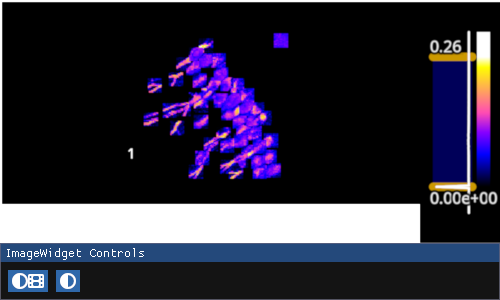

In [52]:
iw = fpl.ImageWidget(imgs.T.max(axis=0), cmap="gnuplot2")
iw.show()


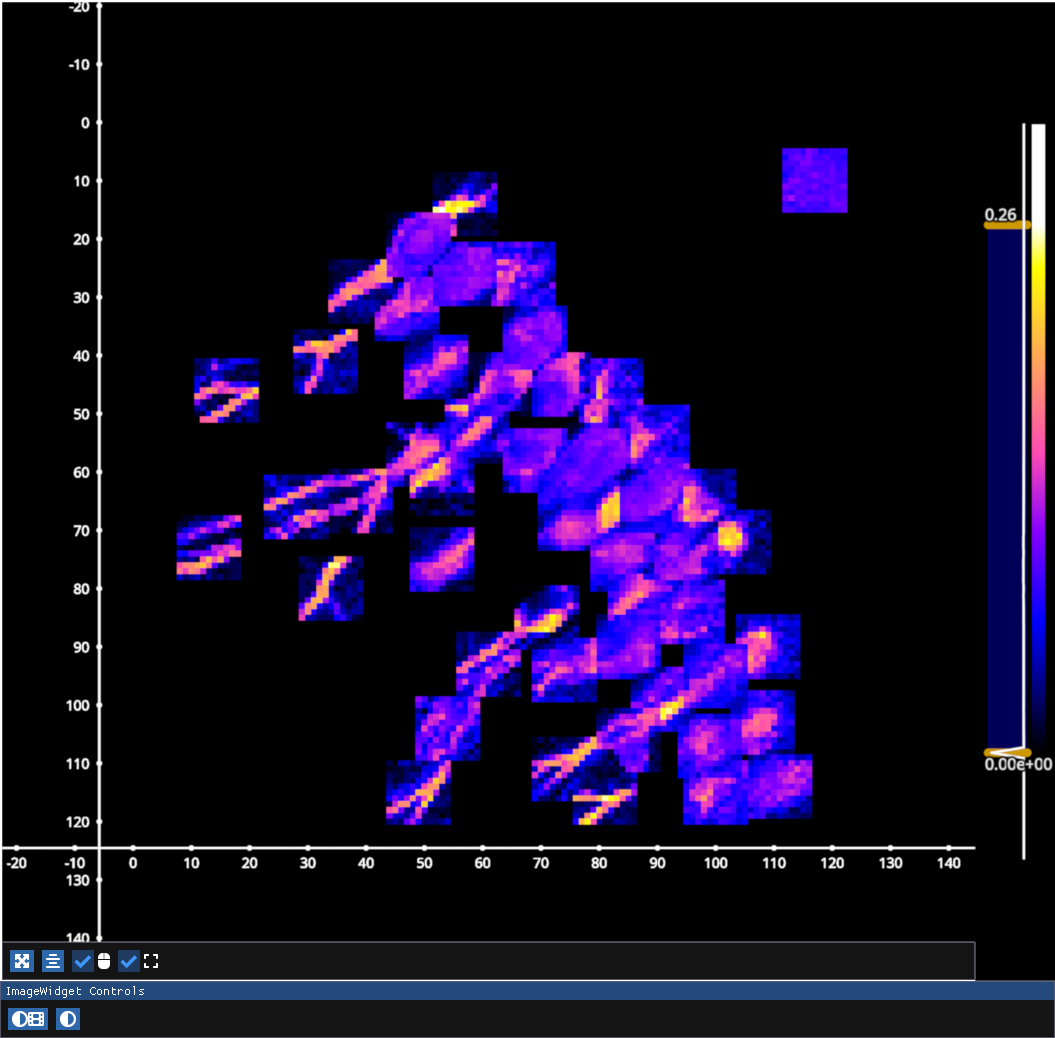

In [56]:
iw.figure.canvas.snapshot()